# Top Ramen Ratings Data Analysis

### Questions and Hypotheses

In this analysis, we aim to answer the following questions to carry out both descriptive and diagnostic analysis:

1. **Which country produces the highest-rated ramen?**
- Hypothesis: Japanese ramen brands generally receive higher ratings than brands from other countries.
2. **Do the ratings scores vary widely in this dataset?** 
- Hypothesis: There will be a wide range of scores as people tend to only give ratings if they have extreme views on either end, very negative or very positive.
3. **Who are the most and least reviewed brands?** 
- Hypothesis: A few popular brands are rated far more than others.
4. **Which brands most consistently receive high average ratings?**
- Hypothesis: A few popular brands will dominate the high ratings.
5. **Do the most reviewed brands also have higher ratings?**
- Hypothesis: Brands with the most reviews have higher average ratings than Brands with fewer ratings.
6. **Does the style of ramen (e.g., cup, bowl, pack) affect its rating?**
- Hypothesis: Ramen served in unusual styles like bottle or can will have lower ratings and traditional styles like box will have the highest ratings.

In [2]:
# import necessary libraries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

In [3]:
df = pd.read_csv('top_ramen_ratings.csv')

In [4]:
df.head()

,Review #,Brand,Variety,Style,Country,Stars,T
0,4120,MIT,Shallot Sauce Dry Noodle,Pack,Taiwan,3,NaN
1,4119,Sapporo Ichiban,Tonkotsu Ramen Japanese Style Noodles,Bowl,United States,4.5,NaN
2,4118,Binh Tay,Mi Kiwi,Bowl,Vietnam,3,NaN
3,4117,Charming Couple,Biang Biang Scallion Chicken Sauce,Pack,Taiwan,4.5,NaN
4,4116,immi,Tom Yum Shrimp Flavor Ramen Soup,Pack,United States,2.75,NaN


In [5]:
df.shape

(4120, 7)

In [6]:
df.isnull().sum()

Review #       0
Brand          0
Variety        0
Style          0
Country        0
Stars          0
T           4120
dtype: int64

In [7]:
df.head()

,Review #,Brand,Variety,Style,Country,Stars,T
0,4120,MIT,Shallot Sauce Dry Noodle,Pack,Taiwan,3,NaN
1,4119,Sapporo Ichiban,Tonkotsu Ramen Japanese Style Noodles,Bowl,United States,4.5,NaN
2,4118,Binh Tay,Mi Kiwi,Bowl,Vietnam,3,NaN
3,4117,Charming Couple,Biang Biang Scallion Chicken Sauce,Pack,Taiwan,4.5,NaN
4,4116,immi,Tom Yum Shrimp Flavor Ramen Soup,Pack,United States,2.75,NaN


In [8]:
df.drop('T', axis='columns', inplace=True)
df.head()

/tmp/ipykernel_3919/2158871137.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop('T', axis='columns', inplace=True)


,Review #,Brand,Variety,Style,Country,Stars
0,4120,MIT,Shallot Sauce Dry Noodle,Pack,Taiwan,3
1,4119,Sapporo Ichiban,Tonkotsu Ramen Japanese Style Noodles,Bowl,United States,4.5
2,4118,Binh Tay,Mi Kiwi,Bowl,Vietnam,3
3,4117,Charming Couple,Biang Biang Scallion Chicken Sauce,Pack,Taiwan,4.5
4,4116,immi,Tom Yum Shrimp Flavor Ramen Soup,Pack,United States,2.75


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4120 entries, 0 to 4119
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Review #  4120 non-null   int64
 1   Brand     4120 non-null   str  
 2   Variety   4120 non-null   str  
 3   Style     4120 non-null   str  
 4   Country   4120 non-null   str  
 5   Stars     4120 non-null   str  
dtypes: int64(1), str(5)
memory usage: 193.3 KB


In [10]:
df['Stars'].value_counts()

Stars
5          775
3.5        607
3.75       581
4          489
4.5        282
3.25       236
4.25       223
3          191
2.75       118
2          104
4.75       103
2.5        102
1.5         54
1           44
0           44
1.75        33
2.25        32
0.5         24
0.25        21
1.25        16
NR           3
Unrated      3
0.75         2
4.25/5       2
1.1          2
3.1          2
4.125        2
2.9          2
2.8          2
NS           1
3.5/2.5      1
4/4          1
5/5          1
4.5/5        1
5/2.5        1
5/4          1
3.50         1
2.1          1
0.9          1
3.125        1
2.125        1
0.1          1
3.7          1
3.4          1
3.6          1
2.85         1
2.3          1
3.2          1
3.65         1
1.8          1
Name: count, dtype: int64

In [11]:
no_stars_mask = (df['Stars'] == 'NS') | (df['Stars'] == 'Unrated') | (df['Stars'] == 'NR')
no_stars_filter = df[no_stars_mask]
no_stars_filter

,Review #,Brand,Variety,Style,Country,Stars
687,3433,Base Foods,Base Noodles,Pack,United States,NS
970,3150,Hakubaku,Baby Somen,Pack,Japan,NR
971,3149,Hakubaku,Baby Udon,Pack,Japan,NR
1479,2641,Nanoblock,Ramen Bokki,Pack,Japan,NR
1572,2548,Ottogi,Plain Instant Noodle No Soup Included,Pack,South Korea,Unrated
1662,2458,Samyang Foods,Sari Ramen,Pack,South Korea,Unrated
2533,1587,Mi E-Zee,Plain Noodles,Pack,Malaysia,Unrated


In [12]:
df = df[~no_stars_mask]
df.shape

(4113, 6)

In [13]:
df['Stars'] = df['Stars'].str.replace(r'/.*', '', regex=True)

In [14]:
df['Stars'].value_counts()

Stars
5        778
3.5      608
3.75     581
4        490
4.5      283
3.25     236
4.25     225
3        191
2.75     118
2        104
4.75     103
2.5      102
1.5       54
1         44
0         44
1.75      33
2.25      32
0.5       24
0.25      21
1.25      16
0.75       2
1.1        2
3.1        2
4.125      2
2.9        2
2.8        2
3.50       1
2.1        1
0.9        1
3.125      1
2.125      1
0.1        1
3.7        1
3.4        1
3.6        1
2.85       1
2.3        1
3.2        1
3.65       1
1.8        1
Name: count, dtype: int64

In [15]:
df.info()

<class 'pandas.DataFrame'>
Index: 4113 entries, 0 to 4119
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Review #  4113 non-null   int64
 1   Brand     4113 non-null   str  
 2   Variety   4113 non-null   str  
 3   Style     4113 non-null   str  
 4   Country   4113 non-null   str  
 5   Stars     4113 non-null   str  
dtypes: int64(1), str(5)
memory usage: 224.9 KB


In [16]:
df['Stars'] = pd.to_numeric(df['Stars'])
df.info()

<class 'pandas.DataFrame'>
Index: 4113 entries, 0 to 4119
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Review #  4113 non-null   int64  
 1   Brand     4113 non-null   str    
 2   Variety   4113 non-null   str    
 3   Style     4113 non-null   str    
 4   Country   4113 non-null   str    
 5   Stars     4113 non-null   float64
dtypes: float64(1), int64(1), str(4)
memory usage: 224.9 KB


In [17]:
df.head()

,Review #,Brand,Variety,Style,Country,Stars
0,4120,MIT,Shallot Sauce Dry Noodle,Pack,Taiwan,3.00
1,4119,Sapporo Ichiban,Tonkotsu Ramen Japanese Style Noodles,Bowl,United States,4.50
2,4118,Binh Tay,Mi Kiwi,Bowl,Vietnam,3.00
3,4117,Charming Couple,Biang Biang Scallion Chicken Sauce,Pack,Taiwan,4.50
4,4116,immi,Tom Yum Shrimp Flavor Ramen Soup,Pack,United States,2.75


In [18]:
unique_countries_sorte = sorted(df['Country'].unique())
unique_countries_sorte

['Australia',
 'Bangladesh',
 'Brazil',
 'Cambodia',
 'Canada',
 'China',
 'Colombia',
 'Dubai',
 'Estonia',
 'Fiji',
 'Finland',
 'France',
 'Germany',
 'Ghana',
 'Holland',
 'Hong Kong',
 'Hungary',
 'India',
 'Indonesia',
 'Ireland',
 'Israel',
 'Italy',
 'Japan',
 'Malaysia',
 'Mexico',
 'Myanmar',
 'Nepal',
 'Netherlands',
 'New Zealand',
 'Nigeria',
 'Pakistan',
 'Peru',
 'Philippines',
 'Phlippines',
 'Poland',
 'Portugal',
 'Russia',
 'Russian Federation',
 'Sarawak',
 'Serbia',
 'Singapore',
 'Souh Korea',
 'South Korea',
 'Spain',
 'Sweden',
 'Taiwan',
 'Thailand',
 'UK',
 'USA',
 'Ukraine',
 'United Kingdom',
 'United States',
 'Vietnam']

In [19]:
countries = {
    'Holland': 'Netherlands',
    'Phlippines': 'Philippines',
    'Russian Federation': 'Russia',
    'Souh Korea': 'South Korea',
    'Sarawak': 'Malaysia',
    'UK': 'United Kingdom',
    'USA': 'United States'
}

df['Country'] = df['Country'].replace(countries)

In [20]:
df['Country'].value_counts()

Country
Japan             797
United States     570
South Korea       428
Taiwan            405
China             286
Thailand          233
Malaysia          230
Hong Kong         205
Indonesia         175
Singapore         144
Vietnam           129
United Kingdom     77
Canada             56
Philippines        54
India              46
Germany            38
Mexico             32
Australia          25
Brazil             24
Netherlands        20
Nepal              14
Myanmar            14
Pakistan           13
Bangladesh         12
Hungary             9
Russia              7
France              6
Poland              6
Colombia            6
Serbia              5
Cambodia            5
Ireland             4
Peru                4
Italy               4
Fiji                4
Spain               3
Israel              3
Ukraine             3
Finland             3
Sweden              3
Dubai               3
Nigeria             2
Ghana               2
Estonia             2
Portugal            1
Ne

In [21]:
df.head()

,Review #,Brand,Variety,Style,Country,Stars
0,4120,MIT,Shallot Sauce Dry Noodle,Pack,Taiwan,3.00
1,4119,Sapporo Ichiban,Tonkotsu Ramen Japanese Style Noodles,Bowl,United States,4.50
2,4118,Binh Tay,Mi Kiwi,Bowl,Vietnam,3.00
3,4117,Charming Couple,Biang Biang Scallion Chicken Sauce,Pack,Taiwan,4.50
4,4116,immi,Tom Yum Shrimp Flavor Ramen Soup,Pack,United States,2.75


In [22]:
unique_brands_sorted = sorted(df['Brand'].unique())
unique_brands_sorted

['1 To 3 Noodles',
 '7 Select',
 '7 Select/Nissin',
 '7-Eleven / Nissin',
 'A-One',
 'A-Sha',
 'A-Sha Dry Noodle',
 'A1',
 'ABC',
 'ABC President',
 'Acecook',
 'Aces',
 'Adabi',
 'Ah Lai',
 'Aji-no-men',
 'Ajinatori',
 'Ajinomoto',
 'Alhami',
 'Amianda',
 'Amino',
 "Annie Chun's",
 'Ao Ba Ba',
 'Aroi',
 'Artisan',
 'Asia Gold',
 'Asian Thai Foods',
 'Assi',
 'Atomy',
 'Authentically Asian',
 'Azami',
 'Baijia',
 'Baixiang',
 'Baixiang Noodles',
 'Baltix',
 'Baman',
 'Bamee',
 'Banzai',
 'Batchelors',
 'Being Blue',
 'Best Wok',
 'Big Bon',
 'Binh Tay',
 'Blount',
 'Bon Go Jang',
 'Bonasia',
 'Boss',
 'Bowlfull',
 'Boys & Girls',
 'Buitoni',
 'Burung Layang Terbang',
 'CJ CheilJedang',
 'COCO 2.0',
 "Campbell's",
 'Canton',
 'Cao Is Starving',
 'Cap Atoom Bulan',
 'CarJEN',
 'Charming Couple',
 "Chaudhary's Wai Wai",
 'Cheetos',
 "Chef Nic's Noodles",
 'Chef Woo',
 'Chencun',
 'Chering Chang',
 'Chewy',
 'Chikara',
 'Chil Kab Farm Products',
 'Chillies Brand',
 'China Best',
 "Ching's 

In [23]:
brand_names_map = {
    'A-Sha Dry Noodle':'A-Sha',
    'ABC President':'ABC',
    'Baixiang Noodles':'Baixiang',
    'ChoripDong':'Chorip Dong',
    'Fantastic Noodles':'Fantastic',
    'Fashion Foods':'Fashion Food',
    'Hua Feng Noodle Expert':'Hua Feng',
    'Ichiran Ramen':'Ichiran',
    'Lau Liu tou':'Lau Liu Tou',
    'Lishan Food Manufacturing':'Lishan',
    'Mr. Lee\'s Noodles':'Mr. Lee\'s',
    'Mr. Noodle':'Mr. Noodles',
    'Nakaki Foods':'Nakaki Food',
    'Nakaki':'Nakaki Food',
    'Nissin ':'Nissin',
    'Nissin Miojo':'Nissin',
    'Nissin-Miojo':'Nissin',
    "O'taste":'O\'Taste',
    "O\'Taste":'O\'Taste',
    'Sakurai Foods':'Sakurai',
    'Samurai Ramen':'Samurai',
    'Seven&I':'Seven & I',
    'Seven & i':'Seven & I',
    'Sugakiya Foods':'Sugakiya',
    'Tablemark':'TableMark',
    'Tasty ly':'Tasty.ly',
    'Thien Houng Foods':'Thien Houng Food',
    'Three Meters Noodles':'Three Meters',
    'Tseng Noodle':'Tseng Noodles',
    'Unif / Tung-I':'Unif',
    'Unif Tung-I':'Unif',
    'Unif-100':'Unif',
    'Yamamoto Seifun':'Yamamoto',
    'Weh Lih':'Wei Lih',
    'Wu Mu':'Wu-Mu',
    'World O Noodle':'World O\' Noodle'
}

df['Brand'] = df['Brand'].replace(brand_names_map)

unique_brands_sorted = sorted(df['Brand'].unique())
unique_brands_sorted

['1 To 3 Noodles',
 '7 Select',
 '7 Select/Nissin',
 '7-Eleven / Nissin',
 'A-One',
 'A-Sha',
 'A1',
 'ABC',
 'Acecook',
 'Aces',
 'Adabi',
 'Ah Lai',
 'Aji-no-men',
 'Ajinatori',
 'Ajinomoto',
 'Alhami',
 'Amianda',
 'Amino',
 "Annie Chun's",
 'Ao Ba Ba',
 'Aroi',
 'Artisan',
 'Asia Gold',
 'Asian Thai Foods',
 'Assi',
 'Atomy',
 'Authentically Asian',
 'Azami',
 'Baijia',
 'Baixiang',
 'Baltix',
 'Baman',
 'Bamee',
 'Banzai',
 'Batchelors',
 'Being Blue',
 'Best Wok',
 'Big Bon',
 'Binh Tay',
 'Blount',
 'Bon Go Jang',
 'Bonasia',
 'Boss',
 'Bowlfull',
 'Boys & Girls',
 'Buitoni',
 'Burung Layang Terbang',
 'CJ CheilJedang',
 'COCO 2.0',
 "Campbell's",
 'Canton',
 'Cao Is Starving',
 'Cap Atoom Bulan',
 'CarJEN',
 'Charming Couple',
 "Chaudhary's Wai Wai",
 'Cheetos',
 "Chef Nic's Noodles",
 'Chef Woo',
 'Chencun',
 'Chering Chang',
 'Chewy',
 'Chikara',
 'Chil Kab Farm Products',
 'Chillies Brand',
 'China Best',
 "Ching's Secret",
 'Chitato',
 'Chongqing Suanlabao Food Co., Ltd.',


In [24]:
df['Brand'].nunique()

580

In [25]:
df.head(15)

,Review #,Brand,Variety,Style,Country,Stars
0,4120,MIT,Shallot Sauce Dry Noodle,Pack,Taiwan,3.00
1,4119,Sapporo Ichiban,Tonkotsu Ramen Japanese Style Noodles,Bowl,United States,4.50
2,4118,Binh Tay,Mi Kiwi,Bowl,Vietnam,3.00
3,4117,Charming Couple,Biang Biang Scallion Chicken Sauce,Pack,Taiwan,4.50
4,4116,immi,Tom Yum Shrimp Flavor Ramen Soup,Pack,United States,2.75
5,4115,Nan Chuan Dao Sheng,Wuhan Sesame Hot Sauce Konjac Rice Noodle,Pack,China,4.50
6,4114,Naked,Chinese Style Orange Chicken Flavor,Pack,United Kingdom,3.75
7,4113,Sapporo Ichiban,Pokemon Noodle Salt & Seafood Flavor,Cup,Japan,2.75
8,4112,Red Chef,Hae Bee Hiam Dried Noodles,Pack,Malaysia,5.00
9,4111,immi,Spicy Beef Flavor Ramen Soup,Pack,United States,3.75


In [26]:
df['Style'].nunique()

9

In [27]:
unique_style_sorted = sorted(df['Style'].unique())
unique_style_sorted

['Bar', 'Bottle', 'Bowl', 'Box', 'Can', 'Cup', 'Pack', 'Restaurant', 'Tray']

In [28]:
# group & aggregate

country_avg = df.groupby('Country')['Stars'].mean().sort_values(ascending=False)
style_avg = df.groupby('Style')['Stars'].mean().sort_values(ascending=False)
brand_avg = df.groupby('Brand')['Stars'].mean().sort_values(ascending=False)


In [29]:
country_avg

Country
France            4.333333
Malaysia          4.201739
Cambodia          4.200000
Indonesia         4.122857
Singapore         4.109375
Spain             4.000000
Myanmar           3.946429
Taiwan            3.913457
Hong Kong         3.880488
South Korea       3.880140
Japan             3.876568
Fiji              3.875000
Brazil            3.645833
Hungary           3.611111
Mexico            3.609375
United States     3.587939
Finland           3.583333
Dubai             3.583333
Ukraine           3.583333
Russia            3.571429
China             3.563112
Germany           3.532895
Nepal             3.517857
Ghana             3.500000
Estonia           3.500000
Bangladesh        3.479167
Thailand          3.475322
India             3.456522
Philippines       3.407407
Peru              3.375000
Colombia          3.291667
Australia         3.260000
Sweden            3.250000
Vietnam           3.221318
Pakistan          3.192308
United Kingdom    3.116883
Poland            3.

Text(0.5, 1.0, 'Average Ramen Ratings by Country')

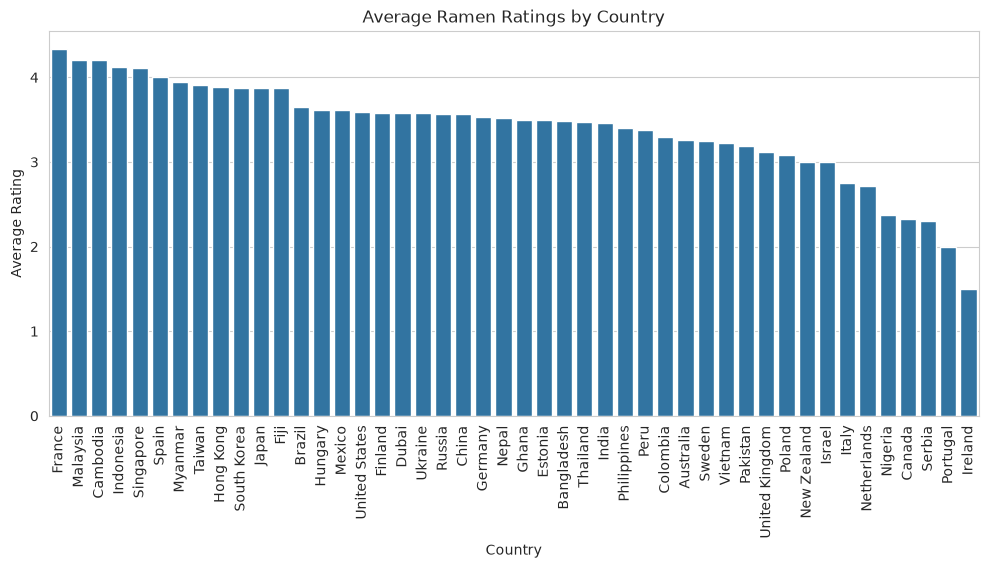

In [30]:
# Bar plot of Average Ratings by Country

plt.figure(figsize=(12, 5))
sns.barplot(x=country_avg.index, y=country_avg.values)
plt.xlabel('Country')
plt.xticks(rotation=90)
plt.ylabel('Average Rating')
plt.title('Average Ramen Ratings by Country')


In [31]:
country_review_counts = df['Country'].value_counts()

print('Number of reviews from France:', country_review_counts.get('France'))

Number of reviews from France: 6


In [32]:
france_reviews = df[df['Country'] == 'France']

print(france_reviews[['Brand', 'Variety', 'Stars']])

               Brand                                Variety  Stars
637          Mr. Min      Original Korean Ramen Beef Flavor   4.25
659          Mr. Min  Original Korean Ramen Instant Noodles   5.00
943  Maison de Coree                 Ramen Gout Coco Poulet   3.75
950  Maison de Coree                   Ramen Gout Carbonara   4.00
967  Maison de Coree                   Ramen Gout BBQ Coree   5.00
975  Maison de Coree                  Ramen Gout Poulet Feu   4.00


Text(0.5, 1.0, 'Distribution of Ramen Ratings')

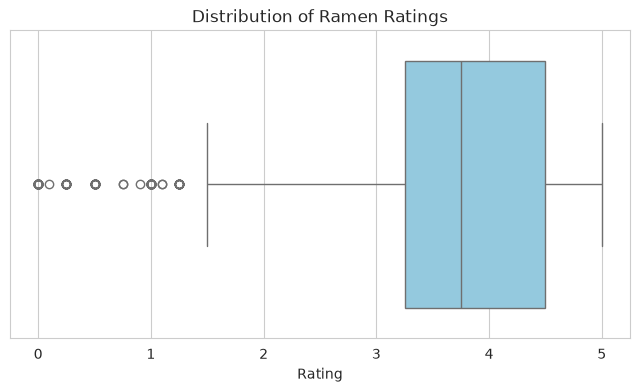

In [33]:
# Do the ratings scores vary widely in the dataset?

plt.figure(figsize=(8, 4))
sns.boxplot(x=df['Stars'], color='skyblue')
plt.xlabel('Rating')
plt.title('Distribution of Ramen Ratings')

Text(0, 0.5, 'Frequency')

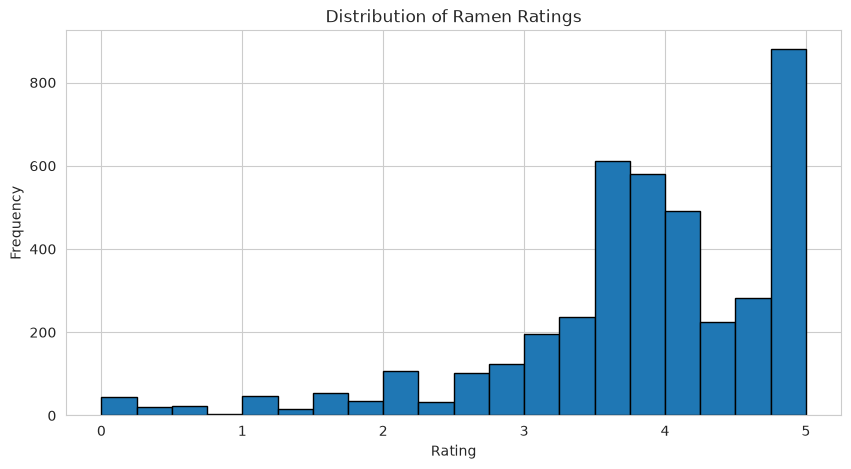

In [34]:
plt.figure(figsize=(10, 5))
plt.hist(df['Stars'], bins=20, edgecolor='black')
plt.title('Distribution of Ramen Ratings')
plt.xlabel('Rating')
plt.ylabel('Frequency')

In [35]:
df['Stars'].describe()

count    4113.000000
mean        3.734780
std         1.043151
min         0.000000
25%         3.250000
50%         3.750000
75%         4.500000
max         5.000000
Name: Stars, dtype: float64

In [36]:
brand_review_counts = df['Brand'].value_counts()
brand_review_counts

Brand
Nissin           530
Maruchan         149
Myojo            133
Nongshim         126
Samyang Foods    103
                ... 
Kim Ve Wong        1
Smack              1
Sutah              1
Tung-I             1
Westbrae           1
Name: count, Length: 580, dtype: int64

Text(0, 0.5, 'Brand Name')

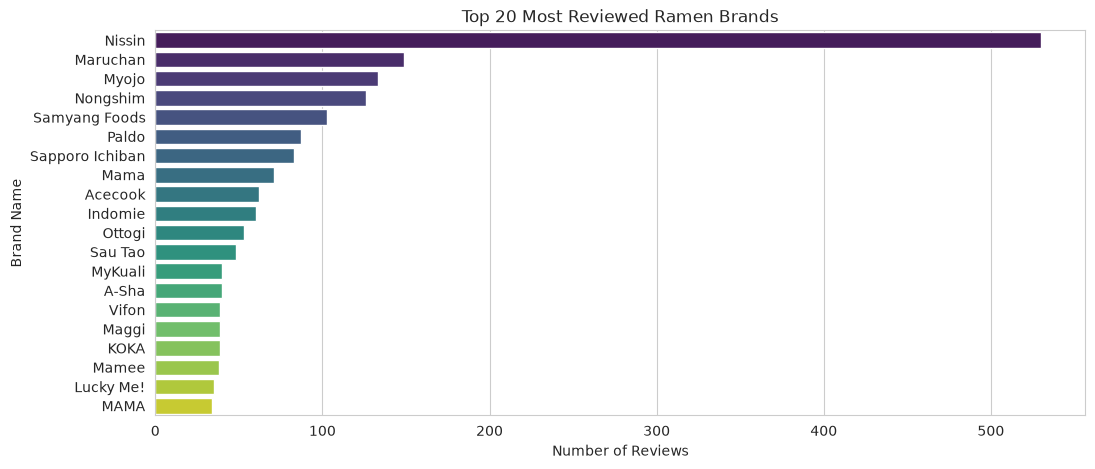

In [37]:
# Top brands in number of reviews

plt.figure(figsize=(12, 5))
sns.barplot(x=brand_review_counts.head(20).values, y=brand_review_counts.head(20).index, hue=brand_review_counts.head(20).index, palette='viridis', legend=False)
plt.title('Top 20 Most Reviewed Ramen Brands')
plt.xlabel('Number of Reviews')
plt.ylabel('Brand Name')

Text(0, 0.5, 'Brand Name')

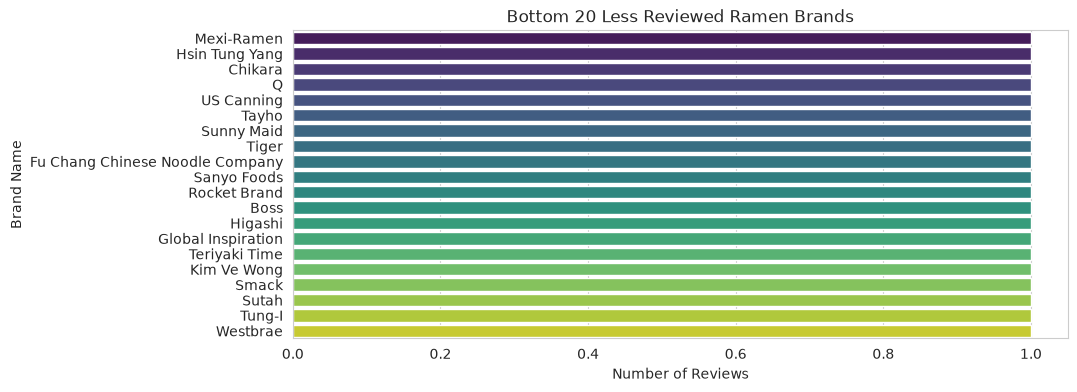

In [38]:
# Bottom 10 less reviewed brands

plt.figure(figsize=(10, 4))
sns.barplot(x=brand_review_counts.tail(20).values, y=brand_review_counts.tail(20).index, hue=brand_review_counts.tail(20).index, palette='viridis', legend=False)
plt.title('Bottom 20 Less Reviewed Ramen Brands')
plt.xlabel('Number of Reviews')
plt.ylabel('Brand Name')

In [39]:
# What brands have the highest ratings?

brand_stats = df.groupby('Brand')['Stars'].agg(['mean', 'count']).rename(columns={'mean': 'Average Rating', 'count': 'Review Count'})
brand_stats

,Average Rating,Review Count
Brand,,
1 To 3 Noodles,4.000000,1
7 Select,3.625000,2
7 Select/Nissin,3.500000,1
7-Eleven / Nissin,4.250000,1
A-One,2.750000,4
...,...,...
Zow Zow,3.750000,1
iMee,3.805556,9
iNoodle,3.312500,4


In [40]:
top_rated_brands = brand_stats[brand_stats['Review Count'] >= 15].sort_values('Average Rating', ascending=False).head(10)
top_rated_brands

,Average Rating,Review Count
Brand,,
MyKuali,4.887500,40
Mom's Dry Noodle,4.666667,18
Vite Ramen,4.323529,17
ABC,4.291667,18
A-Sha,4.268750,40
Marutai,4.250000,15
Mr. Lee's,4.203125,16
Mi Sedaap,4.203125,16
New Touch,4.125000,20


Text(0, 0.5, 'Brand Name')

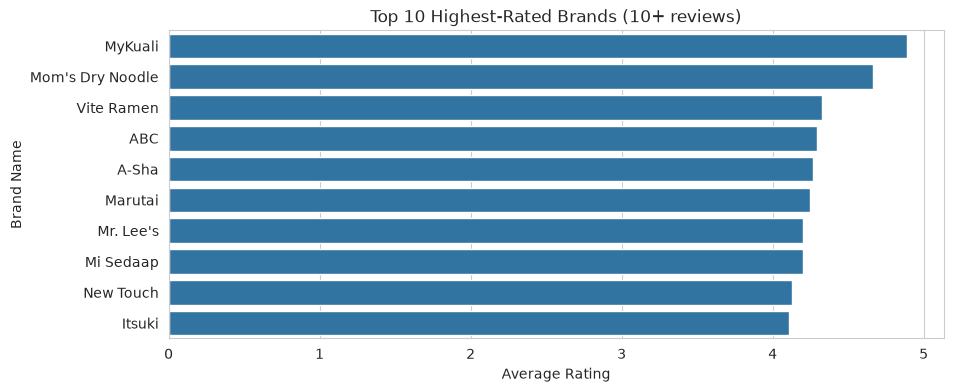

In [41]:
plt.figure(figsize=(10, 4))
sns.barplot(x=top_rated_brands['Average Rating'], y=top_rated_brands.index)
plt.title('Top 10 Highest-Rated Brands (10+ reviews)')
plt.xlabel('Average Rating')
plt.ylabel('Brand Name')

In [42]:
# Most reviewed brands likely to have positive ratings

# number of reviews per brand
brand_review_counts

# average rating per brand
brand_avg_ratings = df.groupby('Brand')['Stars'].mean()

# combine two variables into a DataFrame
brand_reviews_stats = pd.DataFrame({'Review_Count': brand_review_counts, 'Average_Rating': brand_avg_ratings})

brand_reviews_stats

,Review_Count,Average_Rating
Brand,,
1 To 3 Noodles,1,4.000000
7 Select,2,3.625000
7 Select/Nissin,1,3.500000
7-Eleven / Nissin,1,4.250000
A-One,4,2.750000
...,...,...
Zow Zow,1,3.750000
iMee,9,3.805556
iNoodle,4,3.312500


(0.0, 5.0)

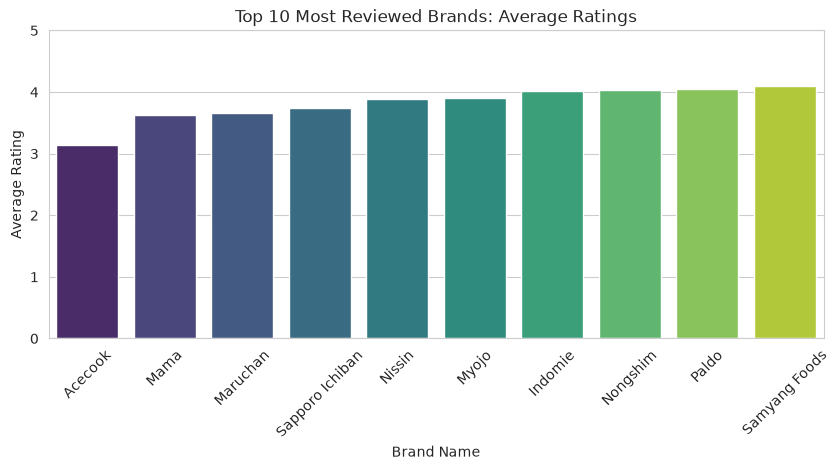

In [43]:
top_10_brands = brand_reviews_stats.sort_values('Review_Count', ascending=False).head(10)
top_10_brands_sorted = top_10_brands.sort_values(by='Average_Rating', ascending=True)

plt.figure(figsize=(10, 4))
sns.barplot(
    x=top_10_brands_sorted.index,
    y=top_10_brands_sorted['Average_Rating'],
    hue=top_10_brands_sorted.index,
    palette=sns.color_palette('viridis', n_colors=10),
    legend=False
)
plt.title('Top 10 Most Reviewed Brands: Average Ratings')
plt.xlabel('Brand Name')
plt.xticks(rotation=45)
plt.ylabel('Average Rating')
plt.ylim(0, 5)


Text(0, 0.5, 'Average Rating')

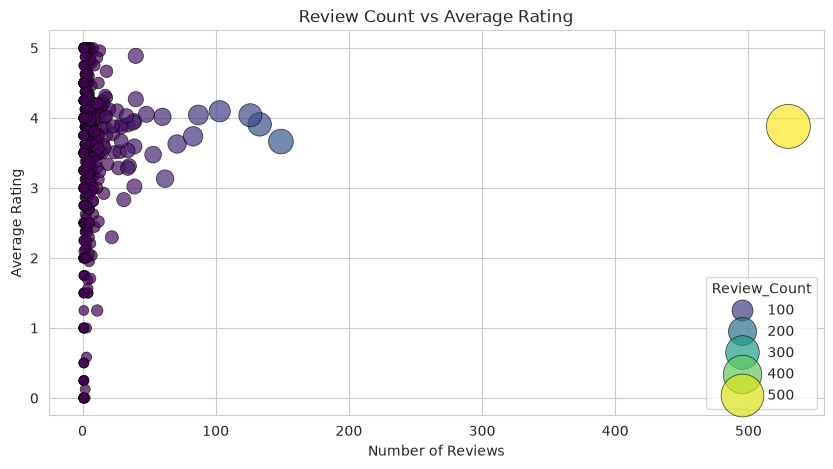

In [44]:
# scatter plot of review count vs average rating

plt.figure(figsize=(10, 5))
sns.scatterplot(
    x=brand_reviews_stats['Review_Count'],
    y=brand_reviews_stats['Average_Rating'],
    size=brand_reviews_stats['Review_Count'],
    sizes=(50, 1000),
    hue=brand_reviews_stats['Review_Count'],
    palette='viridis',
    alpha=0.7,
    edgecolor='black'
)
plt.title('Review Count vs Average Rating')
plt.xlabel('Number of Reviews')
plt.ylabel('Average Rating')

Text(0, 0.5, 'Ratings')

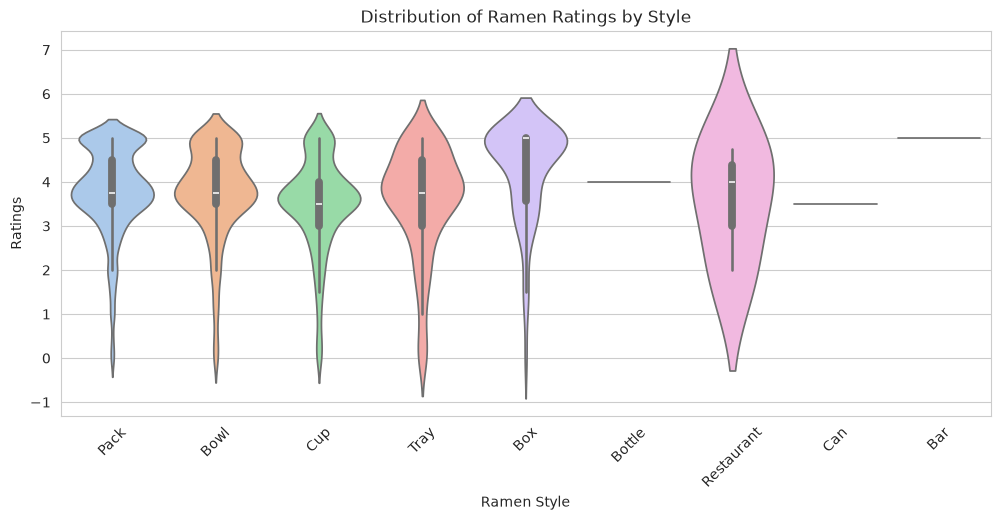

In [45]:
# Ramen Ratings by Style

plt.figure(figsize=(12, 5))
sns.violinplot(
    x='Style',
    y='Stars',
    data=df,
    hue='Style',
    palette='pastel',
    legend=False
)
plt.title('Distribution of Ramen Ratings by Style')
plt.xlabel('Ramen Style')
plt.xticks(rotation=45)
plt.ylabel('Ratings')

## Conclusions

#### Key Findings:

1. Which country produces the highest-rated ramen?
    - 

2. Do the ratings scores vary widely in this dataset?
    - Our hypothesis was ....
    - But the findings showed ....